# 1. Problem Statement

This project uses a telecom customer dataset containing 7,043 customers and 38 columns. The goal is to predict customer churn, which means a customer stops using the company's services.

The target variable is **Customer Status**, which has three categories: Stayed (4,720 customers), Churned (1,869 customers), and Joined (454 customers). Most customers stayed with the company, while fewer customers left. Since the goal is to predict which customers might leave, customers labeled Joined will be excluded.

The remaining categories will be converted into a binary target called **Churn**, where 0 represents Stayed and 1 represents Churned. This is a **binary classification problem** because the model will predict whether a customer stays with the company or leaves. I will use **logistic regression**, which is a classification algorithm despite its name, to predict the probability of customer churn.

# 2. Basic Data Cleaning

In [1]:
import pandas as pd

df = pd.read_csv("telecom_customer_churn.csv")

# keeps stayed and churned customers
df = df[df["Customer Status"].isin(["Stayed", "Churned"])].copy()
df["Churn"] = df["Customer Status"].map({"Stayed": 0, "Churned": 1})

# removes unwanted columns
df = df.drop(columns=[
    "Customer ID", "City", "Zip Code", "Latitude", "Longitude",
    "Customer Status", "Churn Category", "Churn Reason"
])

# addresses missing values
df["Offer"] = df["Offer"].fillna("None")

df["Avg Monthly Long Distance Charges"] = df["Avg Monthly Long Distance Charges"].fillna(0)
df["Avg Monthly GB Download"] = df["Avg Monthly GB Download"].fillna(0)

df["Multiple Lines"] = df["Multiple Lines"].fillna("No")
df["Internet Type"] = df["Internet Type"].fillna("None")

internet_cols = [
    "Online Security", "Online Backup", "Device Protection Plan",
    "Premium Tech Support", "Streaming TV", "Streaming Movies",
    "Streaming Music", "Unlimited Data"
]
df[internet_cols] = df[internet_cols].fillna("No")

# removes duplicates
duplicates = df.duplicated().sum()
df = df.drop_duplicates()

print("Remaining missing values:", df.isnull().sum().sum())
print("Duplicates removed:", duplicates)
print("Dataset shape:", df.shape)


Remaining missing values: 0
Duplicates removed: 0
Dataset shape: (6589, 31)


I removed unnecessary columns, including customer identifiers and information that could reveal the churn outcome. I also excluded customers who had just joined so the model could focus on customers who stayed or left.

I filled missing service information with "No" or "None" and missing usage values with 0. After cleaning, there were no missing values or duplicate rows and the dataset now contains 6,589 customers and 31 columns.


### Checking Categorical Values

I needed to check the unique values in each categorical column to identify inconsistent entries, such as different spellings or labels for the same category. The results show that the categories are consistent, so no corrections are needed.

In [2]:
# checks categorical values
categorical_cols = df.select_dtypes(include=["str", "object"]).columns

for col in categorical_cols:
    print(col, ":", list(df[col].unique()))

Gender : ['Female', 'Male']
Married : ['Yes', 'No']
Offer : ['None', 'Offer E', 'Offer D', 'Offer A', 'Offer B', 'Offer C']
Phone Service : ['Yes', 'No']
Multiple Lines : ['No', 'Yes']
Internet Service : ['Yes', 'No']
Internet Type : ['Cable', 'Fiber Optic', 'DSL', 'None']
Online Security : ['No', 'Yes']
Online Backup : ['Yes', 'No']
Device Protection Plan : ['No', 'Yes']
Premium Tech Support : ['Yes', 'No']
Streaming TV : ['Yes', 'No']
Streaming Movies : ['No', 'Yes']
Streaming Music : ['No', 'Yes']
Unlimited Data : ['Yes', 'No']
Contract : ['One Year', 'Month-to-Month', 'Two Year']
Paperless Billing : ['Yes', 'No']
Payment Method : ['Credit Card', 'Bank Withdrawal', 'Mailed Check']


### Encoding Categorical Variables

Since machine learning models need numerical data to make predictions, I used this step to prepare the categorical features by converting them into numerical columns while avoiding unnecessary duplicate information.

In [3]:
# converts categorical variables to numeric
df_before_encoding = df.copy()
df = pd.get_dummies(df, drop_first=True, dtype=int)

print("Dataset shape after encoding:", df.shape)
print("Remaining categorical columns:", len(df.select_dtypes(include=["str", "object"]).columns))

Dataset shape after encoding: (6589, 39)
Remaining categorical columns: 0


I used pd.get_dummies() to convert the categorical variables into numeric values which created 0/1 columns that can be used by the prediction model. The dataset now has 6,589 rows and 39 columns, with no categorical columns remaining.


### Identifying and Removing Outliers

This step uses boxplots to examine the numerical features for unusually high or low values. I will then use the interquartile range (IQR) method to remove extreme values from Total Revenue that could affect the analysis.

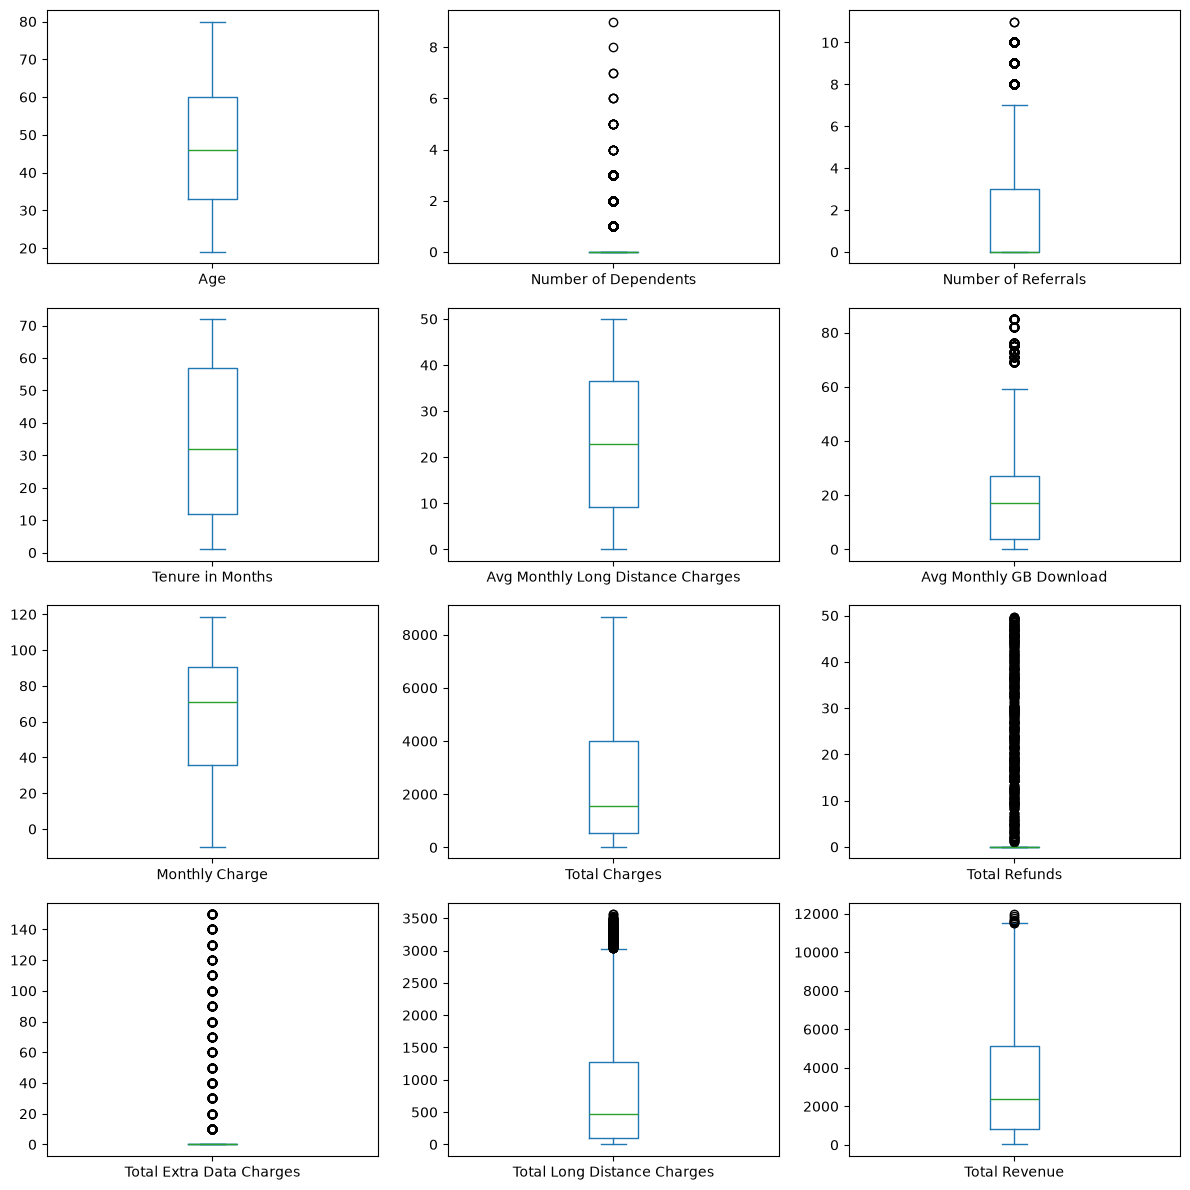

Outliers removed: 9
Dataset shape: (6580, 39)


In [4]:
import matplotlib.pyplot as plt

# checks outliers in numerical features
numeric_cols = [
    "Age", "Number of Dependents", "Number of Referrals",
    "Tenure in Months", "Avg Monthly Long Distance Charges",
    "Avg Monthly GB Download", "Monthly Charge",
    "Total Charges", "Total Refunds", "Total Extra Data Charges",
    "Total Long Distance Charges", "Total Revenue"
]

df[numeric_cols].plot(
    kind="box", subplots=True, layout=(4, 3),
    figsize=(12, 12), sharey=False
)

plt.tight_layout()
plt.show()

# removes total revenue outliers using IQR
Q1 = df["Total Revenue"].quantile(0.25)
Q3 = df["Total Revenue"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

before = len(df)
df = df[df["Total Revenue"].between(lower, upper)].copy()
df_before_encoding = df_before_encoding.loc[df.index].copy()

print("Outliers removed:", before - len(df))
print("Dataset shape:", df.shape)

I used boxplots to examine 12 numerical variables for outliers. Some unusual values, such as higher numbers of dependents or referrals, could still be valid customer information.

I used the IQR method to remove 9 unusually high Total Revenue values. After removing these outliers, the dataset contains 6,580 customers and 39 columns.


### Heatmap Feature Selection
I chose a correlation heatmap to help identify numerical features that contain similar information. The heatmap shows how strongly the features are related to each other, with values closer to 1 or -1 indicating stronger correlations.

The goal is to reduce the number of features by identifying ones that may be redundant. I will use the heatmap to find highly correlated features and remove unnecessary columns while keeping useful information for predicting customer churn.

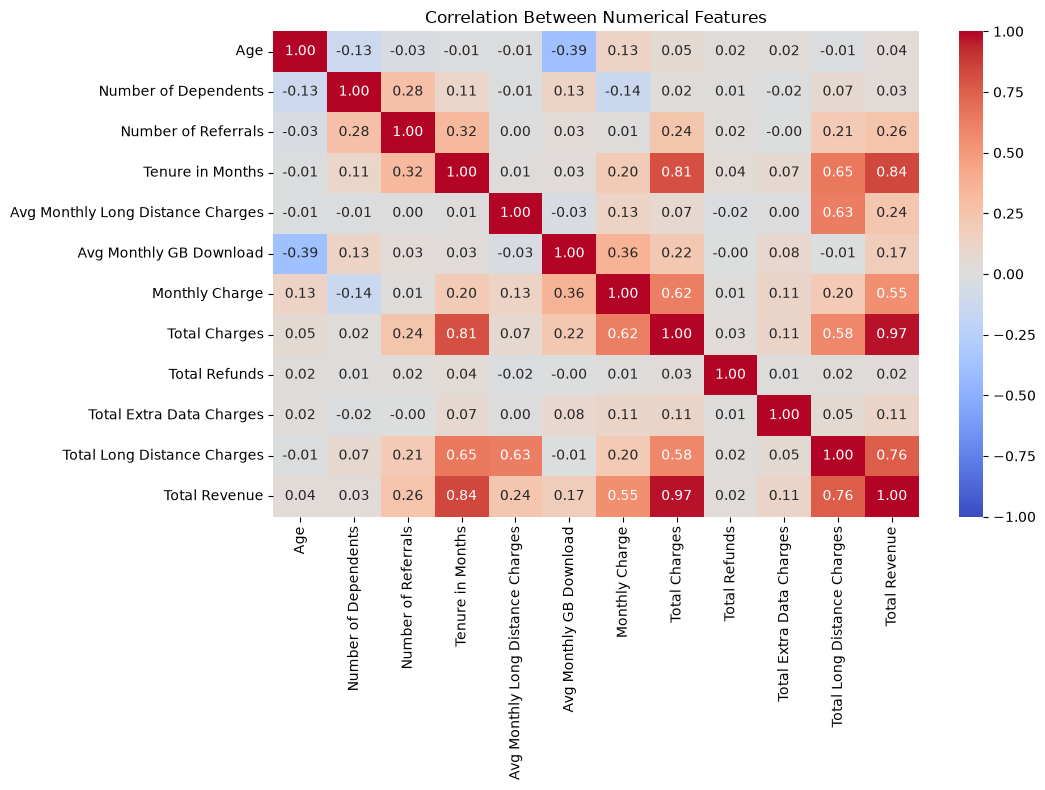

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# checks correlations between numerical predictors
corr = df[numeric_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [6]:
# removes a highly correlated feature
df = df.drop(columns=["Total Revenue"])

print("Dataset shape:", df.shape)

Dataset shape: (6580, 38)


The heatmap showed a very strong correlation of 0.97 between Total Charges and Total Revenue. This suggests that both features contain much of the same information. Tenure in Months also had strong correlations with these features, but I kept Tenure in Months because it measures how long a customer has been with the company, while Total Charges measures how much they've spent which represents different characteristics.

I chose to remove Total Revenue and keep Total Charges to avoid using two highly similar features. This reduced the dataset from 39 columns to 38, including the target variable, while keeping the information needed for further analysis.


### ANOVA Feature Selection

I will use ANOVA to compare numerical features between customers who stayed and customers who churned. ANOVA helps determine whether the differences between the two groups are statistically significant.

The goal is to identify features that may not be useful for predicting churn so I can reduce the number of features in the dataset.

In [7]:
from sklearn.feature_selection import f_classif

# tests numerical features against churn
anova_features = [col for col in numeric_cols if col in df.columns]

f_scores, p_values = f_classif(df[anova_features], df["Churn"])

anova_results = pd.DataFrame({
    "Feature": anova_features,
    "F-score": f_scores,
    "P-value": p_values
}).sort_values("P-value")

print(anova_results.to_string(index=False))

                          Feature     F-score       P-value
                 Tenure in Months 1520.094698 2.485342e-299
              Number of Referrals  711.022526 7.746298e-149
      Total Long Distance Charges  507.252673 2.861570e-108
                    Total Charges  435.010229  1.338174e-93
             Number of Dependents  376.830383  1.135270e-81
                   Monthly Charge  195.835811  7.172635e-44
                              Age   82.205641  1.591959e-19
                    Total Refunds   12.583573  3.918634e-04
          Avg Monthly GB Download   10.744538  1.051305e-03
Avg Monthly Long Distance Charges    0.415380  5.192740e-01
         Total Extra Data Charges    0.000519  9.818183e-01


In [8]:
# removes features not significant in ANOVA
df = df.drop(columns=[
    "Avg Monthly Long Distance Charges",
    "Total Extra Data Charges"
])

print("Dataset shape:", df.shape)

Dataset shape: (6580, 36)


I used scikit-learn's `f_classif` function to perform an ANOVA F-test on the numerical features against customer churn. This function calculates the F-scores and p-values, which I used to determine which features were statistically significant.

Using a p-value cutoff of 0.05, I removed **Avg Monthly Long Distance Charges** and **Total Extra Data Charges** because neither showed a statistically significant difference between customers who stayed and those who churned. This helped reduce the number of features used in the prediction model.

### Chi-Squared Test Feature Selection

Next, I will use the chi-squared test to check whether the categorical features are associated with customer churn. This will help identify which features may be useful for predicting churn and which ones can be removed to reduce the number of predictors.

In [9]:
from scipy.stats import chi2_contingency

# tests original categorical features against churn
categorical_cols = df_before_encoding.select_dtypes(
    include=["str", "object"]
).columns

results = []

for col in categorical_cols:
    table = pd.crosstab(df_before_encoding[col], df_before_encoding["Churn"])
    chi2_stat, p_value, dof, expected = chi2_contingency(table)
    results.append((col, p_value))

# displays p-values
chi2_results = pd.DataFrame(
    results, columns=["Feature", "P-value"]
).sort_values("P-value")

print(chi2_results.to_string(index=False))

               Feature       P-value
              Contract  0.000000e+00
                 Offer 6.981454e-151
         Internet Type 1.766015e-128
      Internet Service  6.239703e-74
        Payment Method  1.343543e-70
       Online Security  2.289398e-55
     Paperless Billing  1.296089e-52
  Premium Tech Support  9.921398e-52
               Married  1.170728e-49
        Unlimited Data  3.510530e-38
         Online Backup  2.014954e-17
Device Protection Plan  9.967863e-14
          Streaming TV  6.634469e-04
      Streaming Movies  1.253011e-03
       Streaming Music  3.203103e-02
        Multiple Lines  2.490176e-01
         Phone Service  2.530581e-01
                Gender  6.183150e-01


The chi-square test showed that 15 categorical features had p-values below 0.05, while three had p-values above 0.05. I chose to remove Phone Service, Multiple Lines, and Gender because they did not show a statistically significant relationship with churn in this test. This helped reduce the number of predictors in the dataset.

In [10]:
# removes categorical features not significant in chi-square
df = df.drop(columns=[
    "Phone Service_Yes",
    "Multiple Lines_Yes",
    "Gender_Male"
], errors="ignore")

print("Dataset shape:", df.shape)

Dataset shape: (6580, 33)


### Variable Variance

In [11]:
# checks variance for all remaining predictors
variances = df.drop(columns=["Churn"]).var()

print(variances.sort_values().to_string())

Payment Method_Mailed Check    4.941788e-02
Offer_Offer C                  5.910108e-02
Offer_Offer A                  7.215264e-02
Offer_Offer D                  8.313169e-02
Offer_Offer E                  8.659080e-02
Offer_Offer B                  1.095626e-01
Internet Type_None             1.625598e-01
Internet Service_Yes           1.625598e-01
Contract_One Year              1.781575e-01
Internet Type_DSL              1.790511e-01
Contract_Two Year              2.022706e-01
Online Security_Yes            2.094216e-01
Premium Tech Support_Yes       2.108786e-01
Unlimited Data_Yes             2.154300e-01
Online Backup_Yes              2.304010e-01
Device Protection Plan_Yes     2.309508e-01
Streaming Music_Yes            2.328736e-01
Payment Method_Credit Card     2.361635e-01
Paperless Billing_Yes          2.395130e-01
Streaming TV_Yes               2.405466e-01
Streaming Movies_Yes           2.412725e-01
Internet Type_Fiber Optic      2.469605e-01
Married_Yes                    2

In summary, I checked the variance of all 32 remaining predictor features to see if any contained very little information. None had zero variance, although some categorical features had relatively low values. Payment Method_Mailed Check had a variance of 0.0494.

I decided not to remove any additional features because low variance alone does not mean a feature is irrelevant to customer churn. The earlier chi-square test also showed that Payment Method had a statistically significant relationship with churn, and therefore, I kept the remaining features for further analysis.

I used ANOVA and chi-square tests to identify features that showed little evidence of a relationship with customer churn. Two numerical features and three categorical features had p-values above 0.05, so I selected them for removal.

These tests helped reduce the number of features in the dataset by removing variables that did not show a statistically significant relationship with churn. However, this does not necessarily mean those features have no predictive value.

I used the correlation heatmap to check whether any numerical features contained overlapping information. Total Charges and Total Revenue had a very strong correlation of 0.97. Tenure in Months was also strongly correlated with both features.

I removed Total Revenue and kept Total Charges to reduce redundancy in the dataset. This eliminated one predictor feature while keeping the other variables for further analysis.

I plan to use logistic regression to predict customer churn, which benefits from standardized numerical features because the variables in this dataset have different scales. For example, Age and Total Charges have very different ranges. I will use StandardScaler after splitting the dataset into training and testing sets to avoid data leakage.

The categorical variables were already converted into numeric dummy variables during data cleaning using pd.get_dummies(). I preserved the original categorical data so the chi-square test could evaluate each feature across all its categories. The dummy variables are represented by 0 and 1, so no additional categorical encoding is needed.

### 4. Prediction Model

I will use scikit-learn's `LogisticRegression` to build a classification model because the goal is to predict whether customers stay or churn. I chose an 80/20 train/test split to evaluate the model on unseen data.

I will check class balance, use `StandardScaler` to standardize numerical features, and evaluate the predictions using accuracy, precision, recall, F1-score, and a confusion matrix.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# separates predictors and target
X = df.drop(columns=["Churn"])
y = df["Churn"]

# splits data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# checks class balance
print("Class proportions:")
print(y.value_counts(normalize=True))

# standardizes numerical features
scale_cols = [col for col in numeric_cols if col in X_train.columns]
scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

# trains logistic regression model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# evaluates predictions
y_pred = model.predict(X_test)

print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Class proportions:
Churn
0    0.715957
1    0.284043
Name: proportion, dtype: float64

Accuracy: 0.8343465045592705

Confusion Matrix:
[[839 103]
 [115 259]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.89      0.89       942
           1       0.72      0.69      0.70       374

    accuracy                           0.83      1316
   macro avg       0.80      0.79      0.79      1316
weighted avg       0.83      0.83      0.83      1316



### Prediction Model and Evaluation

I chose logistic regression because predicting churn is a binary classification problem. The data is somewhat imbalanced (71.6% stayed, 28.4% churned), but I kept the original proportions to evaluate the model first.

I used an 80/20 train/test split to evaluate predictions on unseen data instead of cross-validation.

The model achieved **83.43% accuracy**, with 72% precision, 69% recall, and an F1-score of 0.70 for churned customers. It correctly identified 259 customers who churned but missed 115. Overall, the model performed reasonably well, although it still misses some customers who leave.

To improve the model, I could experiment with class balancing or adjusting the classification threshold to improve churn recall, although this might increase false positives.